# AI for Actuaries : Hackathon 2026

### Objective

Predict the expected ultimate net claim cost (risk premium) for each policy-period in 2025, net of policy excess and recoveries, excluding repudiated claims.

The modelling approach is based on:

$ \text{Expected Claim Cost} = \text{Exposure} \times \text{Frequency} \times \text{Severity} $

## Week 1: Build Your Pricing Approach
At the start of the challenge, you will receive a synthetic insurance data from an established market. The data covers three lines of business: private motor, home buildings and home contents. It runs over four policy years (2021 to 2024) in a developed market.

Your task is to predict the expected ultimate claim cost for each policy in 2025 : the final cost of all claims with a loss date in the row’s period, net of the policy excess and net of recoveries, excluding declined claims.



In [3]:
# Install packages
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
import seaborn as sns

# Models

#warnings.filterwarnings('ignore')

In [4]:
#Read the datasets
from pathlib import Path

data_dir = Path("data")
if not data_dir.is_dir():
    raise FileNotFoundError(f"Data directory not found: {data_dir.resolve()}")

parquet_files = sorted(data_dir.glob("*.parquet"))
if not parquet_files:
    raise FileNotFoundError(f"No Parquet datasets found in {data_dir.resolve()}")

datasets = {path.stem: pd.read_parquet(path) for path in parquet_files}

pd.DataFrame(
    [
        {"dataset": name, "rows": len(df), "columns": len(df.columns), "duplicate rows": df.duplicated().sum()}
        for name, df in datasets.items()
    ]
)

,dataset,rows,columns,duplicate rows
0,addresses,575983,16,0
1,claims,163150,12,0
2,customers,545240,18,0
3,policies_buildings,707726,27,0
4,policies_contents,721617,28,0
5,policies_motor,979968,39,0
6,sample_submission,626639,2,0
7,test_buildings,184155,26,0
8,test_contents,187498,27,0
9,test_motor,254986,38,0


## Data Preparation and Dataset Merging

Objective: Ensure that each row represents a valid policy-period and that reference tables have unique keys. \
Below the table we can see that the average exposure in the policies is more than 1 year.


Before the train test split we do a high level EDA, to understand the structure of the dataset.

In [18]:
customers = datasets["customers"].copy()
addresses = datasets["addresses"].copy()
weather = datasets["weather"].copy()
claims = datasets["claims"].copy()

train = {
    line: datasets[f"policies_{line}"].copy()
    for line in ["motor", "buildings", "contents"]
}

test = {
    line: datasets[f"test_{line}"].copy()
    for line in ["motor", "buildings", "contents"]
}

# 1. Check unique keys
print("=== REFERENCE TABLE CHECKS ===")

for name, df, keys in [
    ("customers", customers, ["customer_id"]),
    ("addresses", addresses, ["address_id"]),
    ("weather", weather, ["address_id", "year"]),
    ("claims", claims, ["claim_id"])
]:
    duplicates = df.duplicated(subset=keys).sum()
    status = "PASS" if duplicates == 0 else "FAIL"
    print(f"{name:20} | {status} | Duplicate keys: {duplicates}")

# 2. Check policy-period structure
print("\n=== POLICY-PERIOD CHECKS ===")

results = []

for line in ["motor", "buildings", "contents"]:
    for dataset_type, df in [
        ("train", train[line]),
        ("test", test[line])
    ]:
        df["period_start"] = pd.to_datetime(df["period_start"])
        df["period_end"] = pd.to_datetime(df["period_end"])

        results.append({
            "dataset": f"{dataset_type}_{line}",
            "rows": len(df),
            "duplicate_row_ids": df["row_id"].duplicated().sum(),
            "invalid_dates": (
                df["period_start"] > df["period_end"]
            ).sum(),
            "missing_exposure": df["exposure"].isna().sum(),
            "nonpositive_exposure": (df["exposure"] <= 0).sum(),
            "total_exposure": df["exposure"].sum(),
            "average_exposure": df["exposure"].mean()
        })

quality_report = pd.DataFrame(results)

display(quality_report)

=== REFERENCE TABLE CHECKS ===
customers            | PASS | Duplicate keys: 0
addresses            | PASS | Duplicate keys: 0
weather              | PASS | Duplicate keys: 0
claims               | PASS | Duplicate keys: 0

=== POLICY-PERIOD CHECKS ===


,dataset,rows,duplicate_row_ids,invalid_dates,missing_exposure,nonpositive_exposure,total_exposure,average_exposure
0,train_motor,979968,0,0,0,0,1.058510e+06,1.080147
1,test_motor,254986,0,0,0,0,1.999836e+05,0.784292
2,train_buildings,707726,0,0,0,0,7.894039e+05,1.115409
3,test_buildings,184155,0,0,0,0,1.502439e+05,0.815856
4,train_contents,721617,0,0,0,0,8.107226e+05,1.123480
5,test_contents,187498,0,0,0,0,1.501238e+05,0.800669


From performing these checks we notice that the exposure has a value that is larger than 1. This is not possible as the description of the dataset indicated that each line in the policy datasets in one calender year for each policy.
Checking the exposures indicates that there are some inconsistencies in the data. 

In [24]:
# Check the exposures:
for line in ["motor", "buildings", "contents"]:

    df = datasets[f"policies_{line}"]

    print(f"\n=== {line.upper()} ===")

    print(df["exposure"].describe(
        percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99]
    ))

    print("Rows with exposure > 1:",
          (df["exposure"] > 1).sum())

    print("Maximum exposure:", df["exposure"].max())

for line in ["motor", "buildings", "contents"]:

    df = datasets[f"policies_{line}"]

    exposure_above_1 = df[df["exposure"] > 1]

    print(f"\n=== {line.upper()} ===")
    print(f"Number of rows with exposure > 1: {len(exposure_above_1)}")

    #display(exposure_above_1)


=== MOTOR ===
count    979968.000000
mean          1.080147
std           9.635858
min           0.002700
1%            0.021900
25%           0.638400
50%           1.000000
75%           1.000000
95%           1.000000
99%           1.000000
max         365.000000
Name: exposure, dtype: float64
Rows with exposure > 1: 3991
Maximum exposure: 365.0

=== BUILDINGS ===
count    707726.000000
mean          1.115409
std           9.779618
min           0.002700
1%            0.027400
25%           0.764400
50%           1.000000
75%           1.000000
95%           1.000000
99%           1.000000
max         365.000000
Name: exposure, dtype: float64
Rows with exposure > 1: 3044
Maximum exposure: 365.0

=== CONTENTS ===
count    721617.00000
mean          1.12348
std          10.16077
min           0.00270
1%            0.02470
25%           0.69860
50%           1.00000
75%           1.00000
95%           1.00000
99%           1.00000
max         365.00000
Name: exposure, dtype: float64
R

In [22]:
# Recalculate exposure quality report

results = []

for line in ["motor", "buildings", "contents"]:
    for dataset_type, df in [
        ("train", train[line]),
        ("test", test[line])
    ]:

        df["period_start"] = pd.to_datetime(df["period_start"])
        df["period_end"] = pd.to_datetime(df["period_end"])

        # Recalculate exposure based on actual days covered
        days_covered = (
            df["period_end"] - df["period_start"]
        ).dt.days + 1

        # Account for leap years
        days_in_year = np.where(
            df["period_start"].dt.is_leap_year,
            366,
            365
        )

        df["exposure_corrected"] = days_covered / days_in_year

        # Build quality report using corrected exposure
        results.append({
            "dataset": f"{dataset_type}_{line}",
            "rows": len(df),
            "duplicate_row_ids": df["row_id"].duplicated().sum(),
            "invalid_dates": (
                df["period_start"] > df["period_end"]
            ).sum(),
            "missing_exposure": df["exposure_corrected"].isna().sum(),
            "nonpositive_exposure": (
                df["exposure_corrected"] <= 0
            ).sum(),
            "total_exposure": df["exposure_corrected"].sum(),
            "average_exposure": df["exposure_corrected"].mean(),
            "max_exposure": df["exposure_corrected"].max(),
            "original_average_exposure": df["exposure"].mean()
        })

quality_report = pd.DataFrame(results)

display(quality_report.round(4))

,dataset,rows,duplicate_row_ids,invalid_dates,missing_exposure,nonpositive_exposure,total_exposure,average_exposure,max_exposure,original_average_exposure
0,train_motor,979968,0,0,0,0,786611.6609,0.8027,1.0,0.8027
1,test_motor,254986,0,0,0,0,199983.5808,0.7843,1.0,0.7843
2,train_buildings,707726,0,0,0,0,590150.5701,0.8339,1.0,0.8339
3,test_buildings,184155,0,0,0,0,150243.9041,0.8159,1.0,0.8159
4,train_contents,721617,0,0,0,0,590449.5397,0.8182,1.0,0.8182
5,test_contents,187498,0,0,0,0,150123.7699,0.8007,1.0,0.8007


In [23]:
# After performing the exposure correction, we will update the original exposure column with the corrected values in both train and test datasets.
for line in train:
    train[line]["exposure"] = train[line]["exposure_corrected"]

for line in test:
    test[line]["exposure"] = test[line]["exposure_corrected"]


Merge customer and adress info.
Objective: Enrich policy-level features before building the target.
These are many-to-one joins: each policy-period belongs to one customer and references one insured address.

In [19]:
def enrich_static_features(df):
    initial_rows = len(df)

    enriched = df.merge(
        customers,
        on="customer_id",
        how="left",
        validate="many_to_one"
    )

    enriched = enriched.merge(
        addresses,
        on="address_id",
        how="left",
        validate="many_to_one"
    )

    assert len(enriched) == initial_rows

    return enriched


train = {
    line: enrich_static_features(df)
    for line, df in train.items()
}

test = {
    line: enrich_static_features(df)
    for line, df in test.items()
}

Step 4 — Engineer historical weather features
Objective: Add weather risk information without using future observations.
We should not use actual weather from 2025 to predict 2025 risk premium. Equally, for a 2023 policy we should not use actual weather outcomes from 2023 when simulating a prediction made at inception.
A starting approach is to use previous-year weather.

In [20]:
# Identify weather variables
weather_columns = [
    col for col in weather.columns
    if col not in ["address_id", "year"]
]

# Rename weather columns
weather_lagged = weather.rename(
    columns={
        "year": "previous_year",
        **{
            col: f"lag1_{col}"
            for col in weather_columns
        }
    }
)

# Function to merge historical weather
def merge_weather(df):

    result = df.copy()

    # Derive year from the policy-period start date
    result["period_start"] = pd.to_datetime(
        result["period_start"]
    )

    result["year"] = result["period_start"].dt.year

    # Use weather from the previous calendar year
    result["previous_year"] = result["year"] - 1

    original_rows = len(result)

    # Merge weather
    result = result.merge(
        weather_lagged,
        on=["address_id", "previous_year"],
        how="left",
        validate="many_to_one"
    )

    # Check that the merge did not duplicate rows
    assert len(result) == original_rows

    return result.drop(columns="previous_year")


# Apply to training datasets
train = {
    line: merge_weather(df)
    for line, df in train.items()
}

# Apply to test datasets
test = {
    line: merge_weather(df)
    for line, df in test.items()
}

Step 5 — Match claims to the correct policy-period
Objective: Assign every historical claim to the exact row covering its loss date.
This is the most important merge in the workflow.
We cannot join claims only on policy_id, because a policy may have multiple rows across different years or mid-term changes.
First, combine the policy-period identifiers into a temporary lookup table.

In [21]:
policy_windows = pd.concat(
    [
        datasets[f"policies_{line}"][
            ["row_id", "policy_id", "period_start", "period_end"]
        ].assign(line=line)
        for line in ["motor", "buildings", "contents"]
    ],
    ignore_index=True
)

policy_windows["period_start"] = pd.to_datetime(
    policy_windows["period_start"]
)
policy_windows["period_end"] = pd.to_datetime(
    policy_windows["period_end"]
)

claims["loss_date"] = pd.to_datetime(claims["loss_date"])

claims_matched = claims.merge(
    policy_windows,
    on=["policy_id", "line"],
    how="left"
)

claims_matched = claims_matched.loc[
    (claims_matched["loss_date"] >= claims_matched["period_start"])
    &
    (claims_matched["loss_date"] <= claims_matched["period_end"])
].copy()

In [22]:
print("Original claims:", len(claims))
print("Matched claims:", len(claims_matched))

print(
    "Claims with multiple matches:",
    claims_matched["claim_id"].duplicated().sum()
)

assert claims_matched["claim_id"].is_unique

unmatched_claims = set(claims["claim_id"]) - set(
    claims_matched["claim_id"]
)

print("Unmatched claims:", len(unmatched_claims))

Original claims: 163150
Matched claims: 162736
Claims with multiple matches: 0
Unmatched claims: 414


### To do

In [23]:
print(unmatched_claims)

{'CL91197655', 'CL88596049', 'CL69757456', 'CL86201783', 'CL97249626', 'CL69974689', 'CL48382153', 'CL25739715', 'CL77758564', 'CL06123265', 'CL30154562', 'CL70287150', 'CL85454617', 'CL84684716', 'CL62134577', 'CL06211240', 'CL46369313', 'CL53075006', 'CL94203490', 'CL80859735', 'CL67839887', 'CL63574747', 'CL99142648', 'CL08400305', 'CL42079678', 'CL85918250', 'CL02793963', 'CL58542155', 'CL40301193', 'CL41346463', 'CL18522494', 'CL14489556', 'CL51509712', 'CL09904317', 'CL62236387', 'CL48545779', 'CL39549417', 'CL41222395', 'CL47614338', 'CL75862771', 'CL65175257', 'CL84959724', 'CL77009095', 'CL71845489', 'CL53108445', 'CL97193436', 'CL86243569', 'CL62473017', 'CL01919149', 'CL02736022', 'CL89591944', 'CL70863409', 'CL08885497', 'CL96988625', 'CL30507532', 'CL80787058', 'CL51707078', 'CL59350221', 'CL52221651', 'CL70071828', 'CL87751628', 'CL73481868', 'CL80742163', 'CL22787366', 'CL12706269', 'CL59418426', 'CL33444715', 'CL67825332', 'CL74498606', 'CL56980938', 'CL91064638', 'CL29

Step 6 — Calculate the observed net incurred claim cost
Objective: Construct a historical cost measure consistent with the target.
According to the data dictionary:
- paid_to_date is already net of excess.
- incurred_to_date consists of paid amounts and the open-claim case estimate.
- recoveries is a separate amount, but it is not confirmed whether incurred already reflects it.
- Repudiated claims must be excluded.
Our provisional assumption is:
\[
\text{Observed Net Incurred}
=
\text{Incurred to Date}
-
\text{Recoveries}
\]

We must not deduct the policy excess again.

In [24]:
claims_matched["eligible"] = (
    claims_matched["status"] != "repudiated"
)

claims_matched["recoveries"] = (
    claims_matched["recoveries"].fillna(0)
)

# Working assumption: recoveries are NOT yet deducted
# from incurred_to_date.
RECOVERIES_ALREADY_NETTED = False

if RECOVERIES_ALREADY_NETTED:
    claims_matched["net_cost_before_status"] = (
        claims_matched["incurred_to_date"]
    )
else:
    claims_matched["net_cost_before_status"] = (
        claims_matched["incurred_to_date"]
        - claims_matched["recoveries"]
    )

claims_matched["observed_net_incurred"] = np.where(
    claims_matched["eligible"],
    claims_matched["net_cost_before_status"],
    0
)

# Final reconciliation:
display(
    claims_matched.groupby(["line", "status"]).agg(
        claims=("claim_id", "count"),
        incurred=("incurred_to_date", "sum"),
        recoveries=("recoveries", "sum"),
        net_cost=("observed_net_incurred", "sum")
    )
)

negative_claims = claims_matched[
    claims_matched["observed_net_incurred"] < 0
]

print("Negative net incurred claims:", len(negative_claims))

claims      incurred   recoveries      net_cost
line      status                                                     
buildings closed       24485  2.165655e+08         0.00  2.165655e+08
          open          1890  3.120311e+07         0.00  3.120311e+07
contents  closed       22944  6.249864e+07         0.00  6.249864e+07
          open           809  3.467941e+06         0.00  3.467941e+06
          repudiated     299  0.000000e+00         0.00  0.000000e+00
motor     closed      103468  3.762674e+08  27613464.36  3.486539e+08
          open          7433  8.194159e+07         0.00  8.194159e+07
          repudiated    1408  0.000000e+00         0.00  0.000000e+00

Negative net incurred claims: 0


In [25]:
## check the AI code, if the sums of columns are correct, so that sum ultimate - recoveries is correct. 

Step 7 — Aggregate claims at policy-period level
Objective: Construct the two historical responses: N and total observed claim cost.
For each policy-period:
\[
N_i=\text{Number of eligible claims}
\]

\[
C_i=\sum_{j\in i}\text{Observed Net Incurred}_{ij}
\]

In [26]:
targets = (
    claims_matched.groupby("row_id")
    .agg(
        N=("eligible", "sum"),
        observed_net_incurred=(
            "observed_net_incurred", "sum"
        )
    )
    .reset_index()
)

targets["N"] = targets["N"].astype(int)

In [27]:
for line in train:
    initial_rows = len(train[line])

    train[line] = train[line].merge(
        targets,
        on="row_id",
        how="left",
        validate="one_to_one"
    )

    assert len(train[line]) == initial_rows

    train[line]["N"] = (
        train[line]["N"].fillna(0).astype(int)
    )

    train[line]["observed_net_incurred"] = (
        train[line]["observed_net_incurred"].fillna(0)
    )

Step 8 — Assess claim development to ultimate
Objective: Correct the mismatch between observed incurred and ultimate costs.
At 31 December 2024:
- Some 2024 losses are not yet reported (IBNR).
- Some reported claims remain open and may develop.
- Future recoveries may not yet be reflected.
Therefore, modelling observed_net_incurred directly will generally underestimate ultimate loss costs if those effects are material.
Ideally, use historical valuation snapshots to build paid/incurred development triangles. However, the supplied claims table has only one snapshot, so reliable chain-ladder development factors cannot be estimated from this table alone.
If validated development-to-ultimate factors become available, you can apply them at a suitable line/peril/accident-year level.

In [28]:
# No estimated development factors are supplied yet.
# These should NOT be treated as genuine ultimate estimates.

for line in train:
    train[line]["development_factor"] = 1.0

    train[line]["model_cost_target"] = (
        train[line]["observed_net_incurred"]
        * train[line]["development_factor"]
    )

How are the target values distributed? 

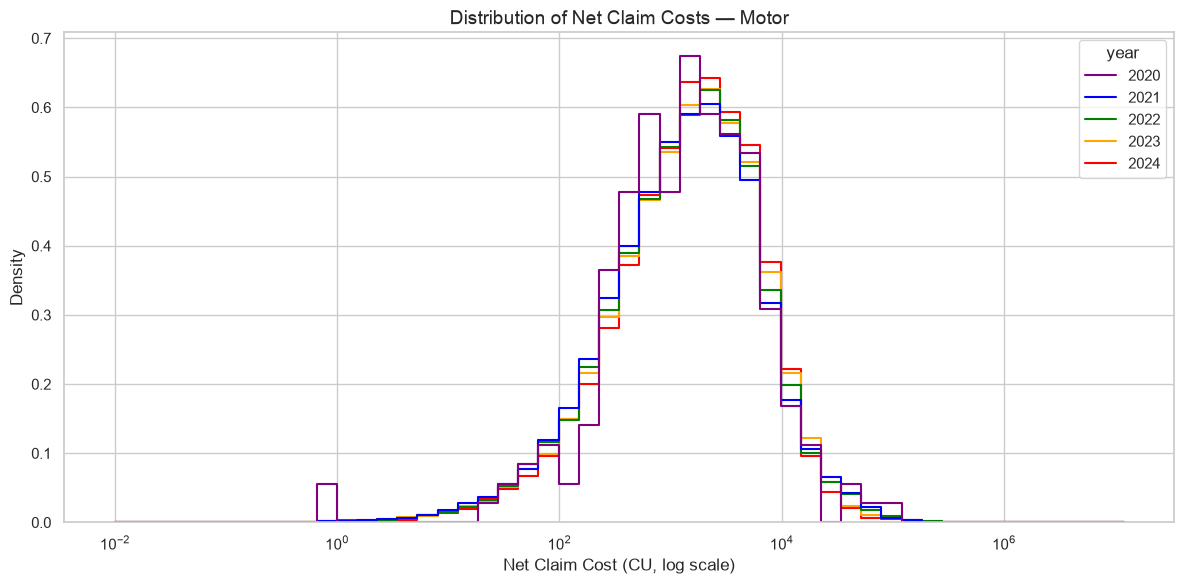

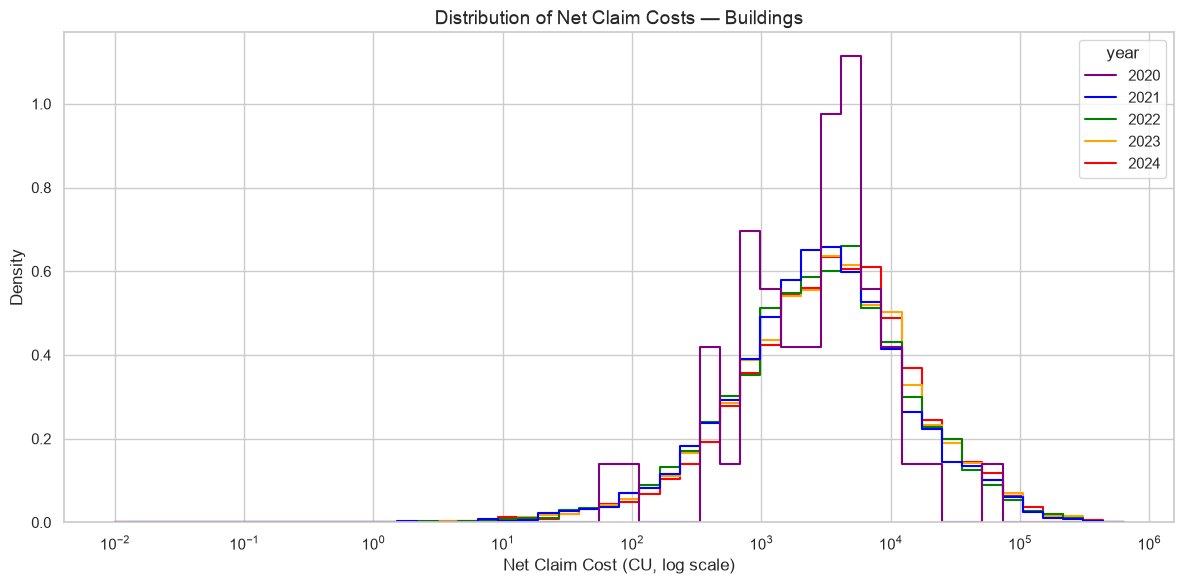

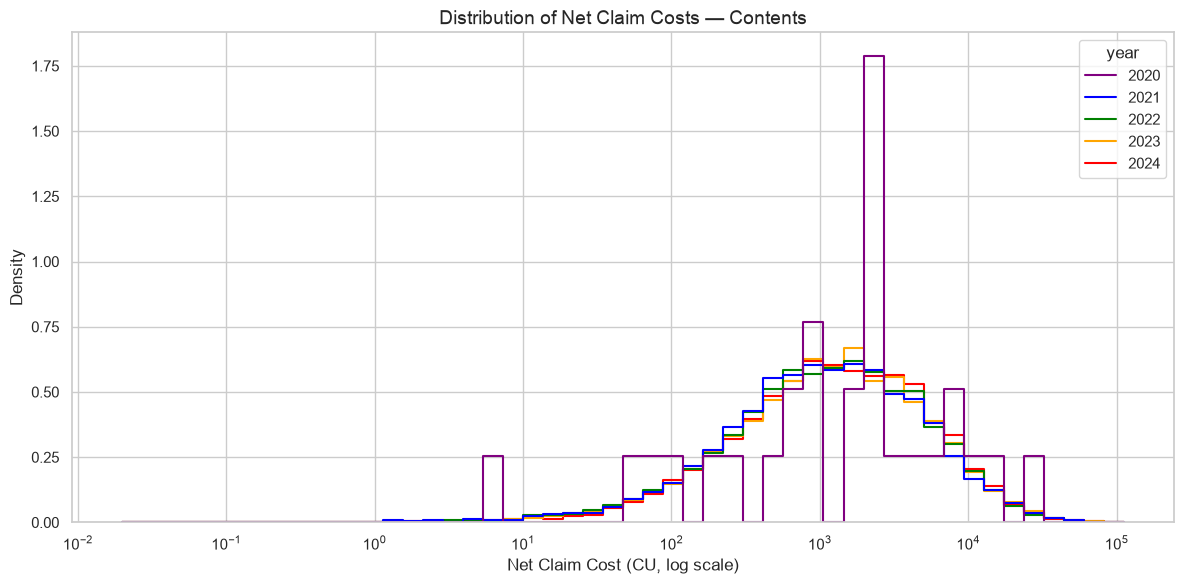

In [34]:
claims_plot = claims.copy()

# Extract accident year from loss date
claims_plot["loss_date"] = pd.to_datetime(claims_plot["loss_date"])
claims_plot["year"] = claims_plot["loss_date"].dt.year

# Exclude repudiated claims
claims_plot = claims_plot[
    claims_plot["status"] != "repudiated"
].copy()

# Provisional assumption: incurred excludes recoveries
claims_plot["net_claim_cost"] = (
    claims_plot["incurred_to_date"]
    - claims_plot["recoveries"].fillna(0)
)

# Retain positive claim costs for log-scaled distribution plots
claims_plot = claims_plot[
    claims_plot["net_claim_cost"] > 0
].copy()

# Define the colors for each accident year
year_colors = {
    2020: "purple",
    2021: "blue",
    2022: "green",
    2023: "orange",
    2024: "red"
}

sns.set_theme(style="whitegrid")

for line in ["motor", "buildings", "contents"]:

    df_line = claims_plot[
        claims_plot["line"] == line
    ].copy()

    plt.figure(figsize=(12, 6))

    sns.histplot(
        data=df_line,
        x="net_claim_cost",
        hue="year",
        palette=year_colors,
        bins=50,
        stat="density",
        common_norm=False,
        element="step",
        fill=False,
        log_scale=True
    )

    plt.title(
        f"Distribution of Net Claim Costs — {line.capitalize()}",
        fontsize=14
    )

    plt.xlabel("Net Claim Cost (CU, log scale)")
    plt.ylabel("Density")
    plt.tight_layout()
    plt.show()

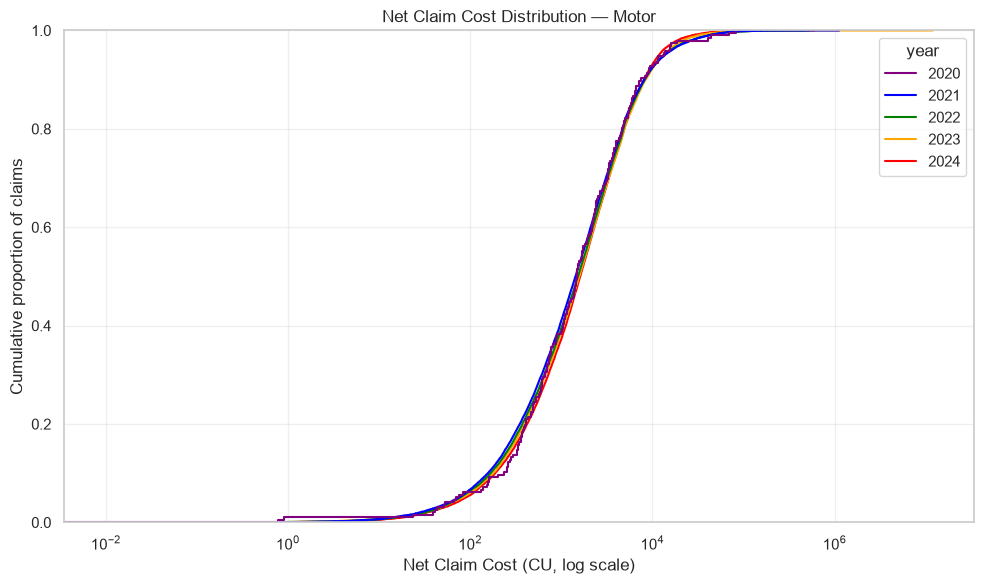

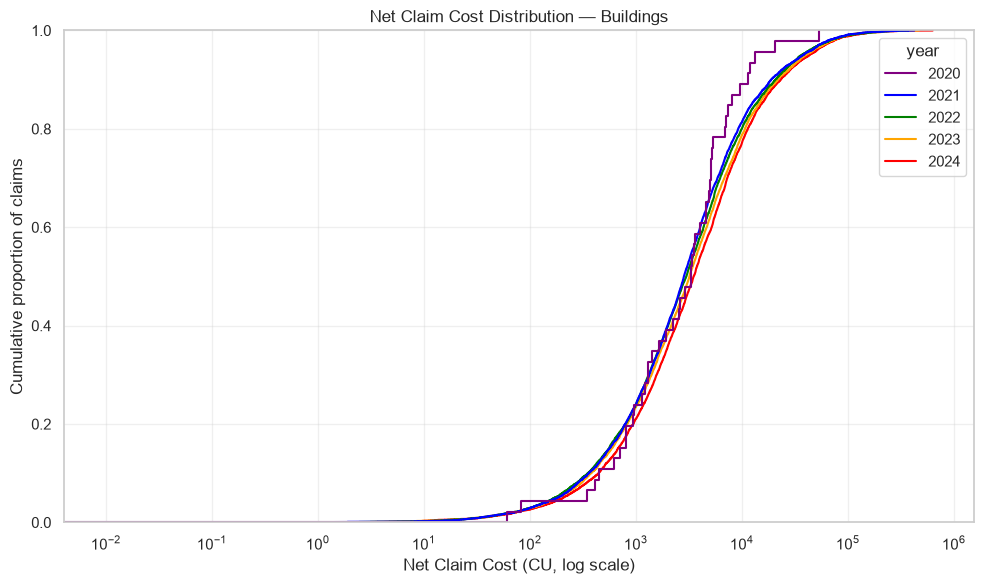

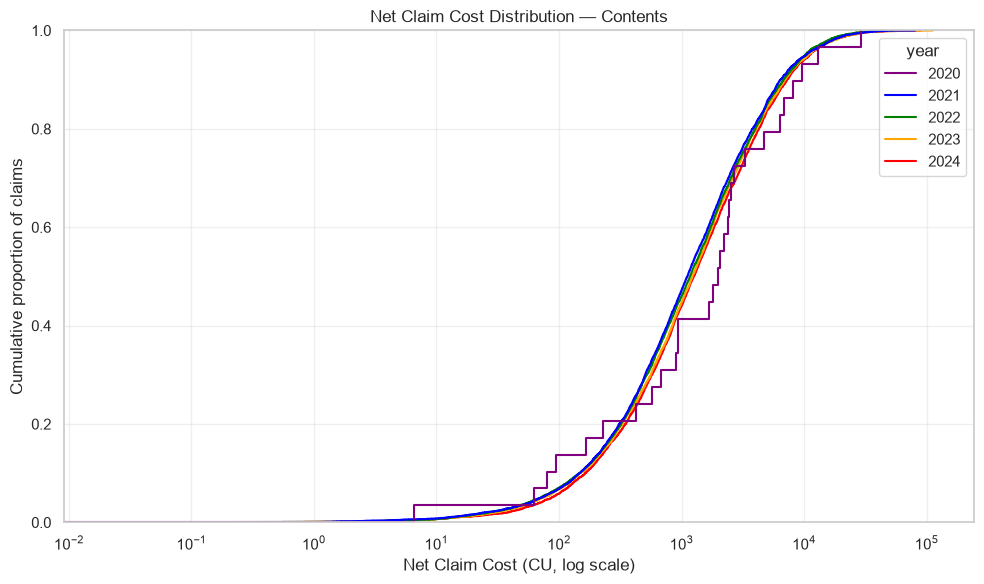

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Limit analysis to training accident years
plot_data = claims_plot[
    claims_plot["year"].between(2020, 2024)
    & (claims_plot["net_claim_cost"] > 0)
].copy()

year_colors = {
    2020: "purple",
    2021: "blue",
    2022: "green",
    2023: "orange",
    2024: "red"
}

for line in ["motor", "buildings", "contents"]:

    df_line = plot_data[plot_data["line"] == line]

    plt.figure(figsize=(10, 6))

    sns.ecdfplot(
        data=df_line,
        x="net_claim_cost",
        hue="year",
        palette=year_colors
    )

    plt.xscale("log")
    plt.title(f"Net Claim Cost Distribution — {line.capitalize()}")
    plt.xlabel("Net Claim Cost (CU, log scale)")
    plt.ylabel("Cumulative proportion of claims")
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

This is particularly useful for identifying whether the differences are in attritional claims or large losses.

In [37]:
severity_comparison = (
    plot_data.groupby(["line", "year"])["net_claim_cost"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        p75=lambda x: x.quantile(0.75),
        p90=lambda x: x.quantile(0.90),
        p95=lambda x: x.quantile(0.95),
        p99=lambda x: x.quantile(0.99)
    )
    .round(2)
)

display(severity_comparison)

count      mean   median      p75       p90       p95  \
line      year                                                          
buildings 2020     46   5174.51  3304.32  5240.14  10577.17  13008.12   
          2021   6204   8715.72  2841.27  7234.92  18919.64  37740.55   
          2022   6797   9059.26  2994.84  7735.89  20790.69  36630.95   
          2023   6824   9519.25  3200.33  8591.47  21849.74  40093.02   
          2024   6571  10250.18  3511.95  9037.26  23241.86  43230.65   
contents  2020     29   3653.99  1971.55  3302.77   8363.06  11601.09   
          2021   5588   2664.55  1115.67  2999.23   6419.81  10361.47   
          2022   6032   2662.37  1169.98  3129.56   6803.28  10215.79   
          2023   6165   2847.99  1228.94  3240.35   6999.66  10747.74   
          2024   5988   2925.19  1258.80  3423.97   7280.88  11049.16   
motor     2020    196   3857.57  1477.74  3707.59   7377.32  12004.90   
          2021  27390   3869.96  1430.54  3795.90   8090.77  13680.50   
          2022  29725   3931.77  1523.13  3923.07   8230.46  13183.71   
          2023  28019   4191.13  1573.46  4069.56   8440.83  13234.20   
          2024  25864   3505.53  1612.45  4050.25   8086.90  11801.65   

                      p99  
line      year             
buildings 2020   38967.89  
          2021   95443.06  
          2022   97097.78  
          2023   96378.70  
          2024  108515.03  
contents  2020   24661.83  
          2021   21562.73  
          2022   20192.41  
          2023   23222.63  
          2024   23419.08  
motor     2020   45107.96  
          2021   41545.08  
          2022   41171.56  
          2023   31770.97  
          2024   27112.57

In [33]:
severity_summary = (
    claims_plot
    .groupby(["line", "year"])["net_claim_cost"]
    .agg(
        claim_count="count",
        mean="mean",
        median="median",
        std="std",
        min="min",
        max="max"
    )
    .round(2)
)

display(severity_summary)

claim_count      mean   median       std    min          max
line      year                                                              
buildings 2020           46   5174.51  3304.32   8420.90  60.37     53968.04
          2021         6204   8715.72  2841.27  21368.71   0.57    424150.00
          2022         6797   9059.26  2994.84  21524.28   1.20    369420.00
          2023         6824   9519.25  3200.33  21982.90   0.01    466446.00
          2024         6571  10250.18  3511.95  24230.64   1.31    631246.21
contents  2020           29   3653.99  1971.55   5855.53   6.59     29215.69
          2021         5588   2664.55  1115.67   4536.88   0.41     80500.00
          2022         6032   2662.37  1169.98   4142.53   0.02     53623.63
          2023         6165   2847.99  1228.94   4947.77   0.08    111900.00
          2024         5988   2925.19  1258.80   4924.34   0.10     89086.41
motor     2020          196   3857.57  1477.74   9026.61   0.77     82206.10
          2021        27390   3869.96  1430.54  11904.18   0.01   1118867.58
          2022        29725   3931.77  1523.13  10844.38   0.05    524358.77
          2023        28019   4191.13  1573.46  71655.69   0.02  11894276.93
          2024        25864   3505.53  1612.45   8263.61   0.01    602049.58

## Train test split.

## EDA

Here we do a more in-depth EDA on the training set.